In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import pandas as pd

# 1. Load and apply the justified TotalCharges fix
df = pd.read_csv("../Dataset/Telco-Customer-Churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.loc[(df["tenure"] == 0) & (df["TotalCharges"].isnull()), "TotalCharges"] = 0.0

# 2. Save the cleaned file (readable labels, kept for Athena)
df.to_csv("../outputs/customers_cleaned.csv", index=False)

# 3. Features and target
X = df.drop(columns=["Churn", "customerID"])
y = (df["Churn"] == "Yes").astype(int)
X["SeniorCitizen"] = X["SeniorCitizen"].map({0: "No", 1: "Yes"})  # treat as categorical

# 4. Split BEFORE fitting any transformer
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# 5. Preprocessing pipeline
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

X_train_processed = preprocess.fit_transform(X_train)   # fit on train only
X_test_processed = preprocess.transform(X_test)         # transform only

print(X_train_processed.shape, X_test_processed.shape)
print("Train churn rate:", y_train.mean().round(3), "| Test churn rate:", y_test.mean().round(3))

(5634, 46) (1409, 46)
Train churn rate: 0.265 | Test churn rate: 0.265


In [3]:
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

# 1. Train both models on the SAME split
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42,
                                            class_weight="balanced", n_jobs=-1),
}
for m in models.values():
    m.fit(X_train_processed, y_train)

# 2. Evaluate on the held-out test set
results = []
for name, m in models.items():
    pred = m.predict(X_test_processed)
    prob = m.predict_proba(X_test_processed)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })
results_df = pd.DataFrame(results).round(3)
print(results_df)

# 3. Confusion matrices
for name, m in models.items():
    print(f"\n{name}\n", confusion_matrix(y_test, m.predict(X_test_processed)))

                 Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
0  Logistic Regression     0.738      0.504   0.783     0.614    0.842
1        Random Forest     0.786      0.628   0.473     0.540    0.821

Logistic Regression
 [[747 288]
 [ 81 293]]

Random Forest
 [[930 105]
 [197 177]]


num__TotalCharges                      0.141
num__tenure                            0.131
num__MonthlyCharges                    0.121
cat__Contract_Month-to-month           0.067
cat__Contract_Two year                 0.037
cat__OnlineSecurity_No                 0.035
cat__TechSupport_No                    0.032
cat__PaymentMethod_Electronic check    0.028
cat__InternetService_Fiber optic       0.025
cat__OnlineBackup_No                   0.018
dtype: float64


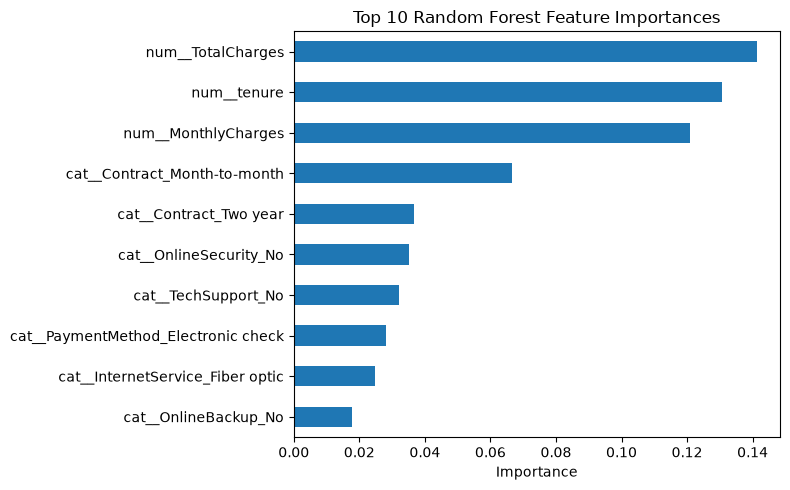


Highest positive (linked to more churn):
 cat__InternetService_Fiber optic       0.72
cat__Contract_Month-to-month           0.66
num__TotalCharges                      0.47
cat__StreamingMovies_Yes               0.28
cat__StreamingTV_Yes                   0.27
cat__PaymentMethod_Electronic check    0.24
cat__OnlineSecurity_No                 0.21
cat__TechSupport_No                    0.17
dtype: float64

Highest negative (linked to less churn):
 num__tenure                                 -1.14
cat__Contract_Two year                      -0.77
num__MonthlyCharges                         -0.68
cat__InternetService_DSL                    -0.62
cat__OnlineSecurity_No internet service     -0.27
cat__OnlineBackup_No internet service       -0.27
cat__InternetService_No                     -0.27
cat__DeviceProtection_No internet service   -0.27
dtype: float64


In [4]:
import matplotlib.pyplot as plt
feature_names = preprocess.get_feature_names_out()

# Random Forest importances
rf = models["Random Forest"]
imp = (pd.Series(rf.feature_importances_, index=feature_names)
         .sort_values(ascending=False).head(10))
print(imp.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
imp[::-1].plot(kind="barh", ax=ax)
ax.set_title("Top 10 Random Forest Feature Importances")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig("../outputs/figures/06_rf_feature_importance.png", dpi=150)
plt.show()

# Logistic Regression coefficients (direction of association)
coef = pd.Series(models["Logistic Regression"].coef_[0], index=feature_names)
print("\nHighest positive (linked to more churn):\n", coef.sort_values(ascending=False).head(8).round(2))
print("\nHighest negative (linked to less churn):\n", coef.sort_values().head(8).round(2))

In [6]:
# Metrics table
results_df.to_csv("../outputs/model_metrics.csv", index=False)

# Predictions from the better model (by F1, change if you prefer recall)
best_name = results_df.sort_values("F1-score", ascending=False).iloc[0]["Model"]
best = models[best_name]
print("Selected model:", best_name)

preds = pd.DataFrame({
    "customerID": df.loc[X_test.index, "customerID"].values,
    "predicted_churn": best.predict(X_test_processed),
    "churn_probability": best.predict_proba(X_test_processed)[:, 1].round(4),
    "model": best_name,
})
preds.to_csv("../outputs/churn_predictions.csv", index=False)

# Model file (preprocessing + model, both needed to reuse it)
joblib.dump({"preprocess": preprocess, "model": best, "name": best_name},
            "../outputs/best_churn_model.joblib")

Selected model: Logistic Regression


['../outputs/best_churn_model.joblib']